In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging

from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import matplotlib.pyplot as plt
import lime.lime_tabular

from models.train_model import get_model
from utils.plotting import plot_single_valuation
from utils.evaluation import evaluate_model

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [ ]:
DATASET_NAME = "yield_synthetic"
MODEL_NAME = "svm"
SCORING = "accuracy"
METHODS = "lime"

RANDOM_STATE = 42

OUTPUT_DIR = Path(f"./output/feature_valuation/{DATASET_NAME}_{MODEL_NAME}_{SCORING}_{METHODS}_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [54]:
def load_dataset(name: str):
    path_map = {
        "breast_cancer": "datasets/breast_cancer/breast_cancer_preprocessed.npz",
        "congress": "../datasets/congress/congress_preprocessed.npz",
        "wine": "../datasets/wine/wine_preprocessed.npz",
        "apple_quality": "../datasets/apple_quality/apple_quality_preprocessed_no_scaling.npz",
        "yield_synthetic": "../datasets/yield_synthetic/yield_preprocessed.npz"
    }
    path = Path(path_map[name])
    data = np.load(path, allow_pickle=True)
    feature_names = data["feature_names"].tolist() if "feature_names" in data else [f"f{i}" for i in range(data["X_train"].shape[1])]
    return data["X_train"], data["X_test"], data["y_train"], data["y_test"], feature_names

In [55]:
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

In [56]:
X_train, X_test, y_train, y_test, feature_names = load_dataset(DATASET_NAME)
scorer = get_scorer(SCORING)

In [41]:
model = get_model(MODEL_NAME, RANDOM_STATE)
model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'


In [42]:
print(f"Dataset: {DATASET_NAME}")
print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"Features: {feature_names}")
print(f"Model trained: {type(model).__name__}")

Dataset: yield_synthetic
Train shape: (800, 4)
Test shape: (200, 4)
Features: ['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
Model trained: Pipeline


In [43]:
from lime.lime_tabular import LimeTabularExplainer

unique_classes = np.unique(y_train)
n_classes = len(unique_classes)

print(f"Number of classes: {n_classes}")
print(f"Class labels: {unique_classes}")

Number of classes: 3
Class labels: [0 1 2]


In [44]:
explainer = LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    class_names=['Low', 'Medium', 'High'],  # 3-class classification
    mode='classification',
    random_state=RANDOM_STATE
)

print("\nLIME explainer created successfully!")
print(f"Training data shape: {X_train.shape}")
print(f"Feature names: {feature_names}")
print(f"Classes: {explainer.class_names}")


LIME explainer created successfully!
Training data shape: (800, 4)
Feature names: ['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
Classes: ['Low', 'Medium', 'High']


In [45]:
test_instance = X_test[0]

print("Test instance:")
for i, (feat, val) in enumerate(zip(feature_names, test_instance)):
    print(f"  {feat}: {val:.4f}")

# Get model's prediction for this instance
prediction = model.predict([test_instance])[0]
prediction_proba = model.predict_proba([test_instance])[0]

print(f"\nModel prediction: Class {prediction}")
print(f"Prediction probabilities:")
for i, (class_name, prob) in enumerate(zip(['Low', 'Medium', 'High'], prediction_proba)):
    print(f"  {class_name}: {prob:.4f}")

# Get LIME explanation for this instance
exp = explainer.explain_instance(
    test_instance,
    model.predict_proba,  # Model's predict_proba method
    num_features=4  # Explain all 4 features
)

print("\nLIME explanation (feature importance for this prediction):")
for feat, weight in exp.as_list():
    print(f"  {feat}: {weight:.4f}")

Test instance:
  Nitrogen: 256.3008
  Irrigation: 366.5678
  Precipitation: 329.4104
  Herbicide: 2753.3646

Model prediction: Class 2
Prediction probabilities:
  Low: 0.0287
  Medium: 0.1299
  High: 0.8414

LIME explanation (feature importance for this prediction):
  327.12 < Irrigation <= 377.90: 0.1427
  Precipitation > 237.22: -0.0430
  Herbicide <= 3628.68: 0.0284
  240.38 < Nitrogen <= 259.38: 0.0129


In [46]:
print("Computing LIME feature importance across test set...")

n_samples = 200
n_features = len(feature_names)

lime_weights = {fname: [] for fname in feature_names}

sample_indices = np.random.choice(len(X_test), min(n_samples, len(X_test)), replace=False)

for idx in sample_indices:
    instance = X_test[idx]

    exp = explainer.explain_instance(
        instance,
        model.predict_proba,
        num_features=n_features
    )

    exp_list = exp.as_list()

    for feature_str, weight in exp_list:
        # Match feature name in the string
        for fname in feature_names:
            if fname in feature_str:
                lime_weights[fname].append(abs(weight))  # Use absolute value
                break

# Compute average importance for each feature
lime_importance = np.array([
    np.mean(lime_weights[fname]) if lime_weights[fname] else 0
    for fname in feature_names
])

print("\nLIME Feature Importance (averaged over {} samples):".format(n_samples))
for fname, importance in zip(feature_names, lime_importance):
    print(f"  {fname}: {importance:.4f}")

Computing LIME feature importance across test set...

LIME Feature Importance (averaged over 200 samples):
  Nitrogen: 0.0380
  Irrigation: 0.2056
  Precipitation: 0.0413
  Herbicide: 0.0273



Plot saved to: output/feature_valuation/yield_synthetic_svm_accuracy_lime_results/yield_synthetic_svm_lime_accuracy.png


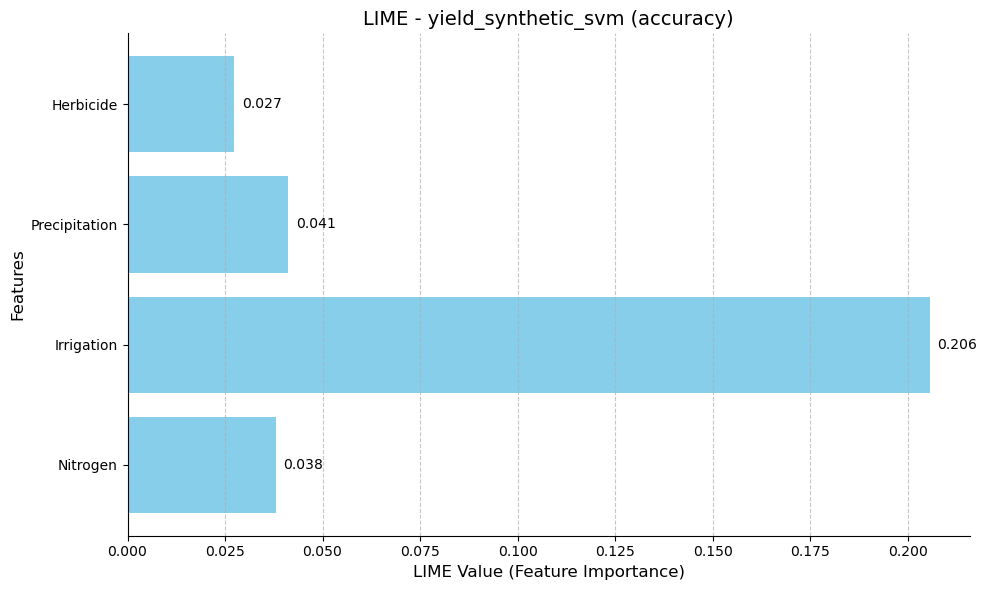

In [47]:
plot_single_valuation(
    lime_importance,
    feature_names,
    method_name="LIME",
    title=f"LIME - {DATASET_NAME}_{MODEL_NAME} ({SCORING})",
    output_path=OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_lime_{SCORING}.png"
)

print(f"\nPlot saved to: {OUTPUT_DIR / f'{DATASET_NAME}_{MODEL_NAME}_lime_{SCORING}.png'}")

In [48]:
# Step 7a: Normalize LIME importance values
lime_norm = lime_importance / lime_importance.sum()

print("\nNormalized LIME Feature Importance:")
for fname, importance in zip(feature_names, lime_norm):
    print(f"  {fname}: {importance:.4f}")

print(f"\nSum of normalized values: {lime_norm.sum():.4f}")


Normalized LIME Feature Importance:
  Nitrogen: 0.1216
  Irrigation: 0.6589
  Precipitation: 0.1322
  Herbicide: 0.0873

Sum of normalized values: 1.0000


In [49]:
ground_truth = pd.Series({
    "Nitrogen": 2.764945,
    "Irrigation": 3.706509,
    "Precipitation": 2.052278,
    "Herbicide": 0.817947
}, name="GroundTruth")

gt_norm = ground_truth / ground_truth.sum()

In [50]:
df_val = pd.DataFrame([
    {"method": "lime", "feature": feature_names[i], "value": v}
    for i, v in enumerate(lime_importance)
])

print("\nDataFrame created:")
print(df_val)


DataFrame created:
  method        feature     value
0   lime       Nitrogen  0.037952
1   lime     Irrigation  0.205614
2   lime  Precipitation  0.041257
3   lime      Herbicide  0.027252



Comparison with Ground Truth 
  method  Spearman   Pearson  CosineSim      MAPE
0   lime       0.8  0.787167   0.884582  0.412648


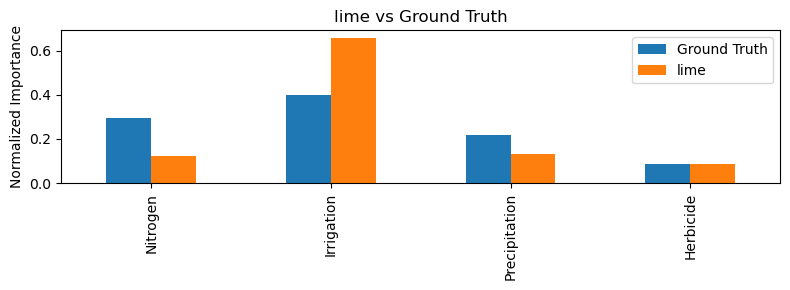

In [51]:
results = []

for method in df_val["method"].unique():
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]

    subset_norm = subset / subset.sum()

    subset_norm = subset_norm[gt_norm.index]

    spearman_corr, _ = spearmanr(gt_norm, subset_norm)
    pearson_corr, _ = pearsonr(gt_norm, subset_norm)
    cos_sim = np.dot(gt_norm, subset_norm) / (norm(gt_norm) * norm(subset_norm))
    mape = (abs(gt_norm - subset_norm) / gt_norm).mean()

    results.append({
        "method": method,
        "Spearman": spearman_corr,
        "Pearson": pearson_corr,
        "CosineSim": cos_sim,
        "MAPE": mape
    })


results_df = pd.DataFrame(results).sort_values("CosineSim", ascending=False)
print("\nComparison with Ground Truth ")
print(results_df)


methods_to_plot = df_val["method"].unique()

fig, axes = plt.subplots(len(methods_to_plot), 1, figsize=(8, 3*len(methods_to_plot)))
if len(methods_to_plot) == 1:
    axes = [axes]

for ax, method in zip(axes, methods_to_plot):
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset / subset.sum()
    subset_norm = subset_norm[gt_norm.index]

    pd.DataFrame({
        "Ground Truth": gt_norm,
        method: subset_norm
    }).plot(kind='bar', ax=ax)

    ax.set_title(f"{method} vs Ground Truth")
    ax.set_ylabel("Normalized Importance")

plt.tight_layout()
plt.show()